In [1]:
!pip -q install xgboost openpyxl

In [2]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_curve
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from xgboost import XGBClassifier

from scipy.stats import wilcoxon, friedmanchisquare

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving Cardiovascular_Disease_Dataset.csv to Cardiovascular_Disease_Dataset.csv
Uploaded files:
Cardiovascular_Disease_Dataset.csv


In [4]:
CSV_FILE = "Cardiovascular_Disease_Dataset.csv"

if not os.path.exists(CSV_FILE):
    # fallback: use first uploaded CSV
    csv_files = [f for f in uploaded.keys() if f.lower().endswith(".csv")]
    if len(csv_files) == 0:
        raise FileNotFoundError(
            "CSV file not found. Please upload Cardiovascular_Disease_Dataset.csv"
        )
    CSV_FILE = csv_files[0]

data = pd.read_csv(CSV_FILE)

print("Dataset loaded successfully.")
print("File:", CSV_FILE)
print("Shape:", data.shape)

display(data.head())

Dataset loaded successfully.
File: Cardiovascular_Disease_Dataset.csv
Shape: (1000, 14)


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1


In [5]:
print("Columns:")
print(list(data.columns))

print("\nData types:")
display(data.dtypes)

print("\nMissing values:")
display(data.isnull().sum())

print("\nTarget distribution:")
display(data["target"].value_counts())

print("\nTarget percentage:")
display(data["target"].value_counts(normalize=True) * 100)

Columns:
['patientid', 'age', 'gender', 'chestpain', 'restingBP', 'serumcholestrol', 'fastingbloodsugar', 'restingrelectro', 'maxheartrate', 'exerciseangia', 'oldpeak', 'slope', 'noofmajorvessels', 'target']

Data types:


,0
patientid,int64
age,int64
gender,int64
chestpain,int64
restingBP,int64
serumcholestrol,int64
fastingbloodsugar,int64
restingrelectro,int64
maxheartrate,int64
exerciseangia,int64



Missing values:


,0
patientid,0
age,0
gender,0
chestpain,0
restingBP,0
serumcholestrol,0
fastingbloodsugar,0
restingrelectro,0
maxheartrate,0
exerciseangia,0



Target distribution:


,count
target,
1,580
0,420



Target percentage:


,proportion
target,
1,58.0
0,42.0


In [6]:
target_col = "target"

# Patient ID is NOT a predictive clinical feature
if "patientid" in data.columns:
    data_model = data.drop(columns=["patientid"]).copy()
else:
    data_model = data.copy()

# Separate X and y
X = data_model.drop(columns=[target_col]).copy()
y = data_model[target_col].astype(int).copy()

print("Feature columns:")
for i, col in enumerate(X.columns, 1):
    print(f"{i}. {col}")

print("\nNumber of features:", X.shape[1])
print("Number of samples:", X.shape[0])

Feature columns:
1. age
2. gender
3. chestpain
4. restingBP
5. serumcholestrol
6. fastingbloodsugar
7. restingrelectro
8. maxheartrate
9. exerciseangia
10. oldpeak
11. slope
12. noofmajorvessels

Number of features: 12
Number of samples: 1000


In [7]:
# Convert all feature columns to numeric where possible
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Remove rows with missing target
valid_target = y.notna()

X = X.loc[valid_target].reset_index(drop=True)
y = y.loc[valid_target].reset_index(drop=True)

# Median imputation for any naturally missing baseline feature values
for col in X.columns:
    if X[col].isnull().any():
        X[col] = X[col].fillna(X[col].median())

print("Final dataset shape:", X.shape)
print("Missing values after baseline cleaning:")
print(X.isnull().sum().sum())

Final dataset shape: (1000, 12)
Missing values after baseline cleaning:
0


In [8]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training samples:", len(X_train_raw))
print("Testing samples :", len(X_test_raw))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 800
Testing samples : 200

Training class distribution:
target
1    464
0    336
Name: count, dtype: int64

Testing class distribution:
target
1    116
0     84
Name: count, dtype: int64


In [9]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("model", DecisionTreeClassifier(
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            probability=True,
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ]),

    "XGBoost": Pipeline([
        ("model", XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

print("Models:")
for name in models:
    print("-", name)

Models:
- Logistic Regression
- Decision Tree
- Random Forest
- SVM
- KNN
- XGBoost


In [10]:
def evaluate_model(model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = model.decision_function(X_test)

    result = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob),
        "PR_AUC": average_precision_score(y_test, y_prob),
        "MCC": matthews_corrcoef(y_test, y_pred)
    }

    return model, result, y_pred, y_prob

In [11]:
baseline_results = []
fitted_models = {}
baseline_predictions = {}

for name, model in models.items():

    fitted_model, result, y_pred, y_prob = evaluate_model(
        model,
        X_train_raw,
        y_train,
        X_test_raw,
        y_test
    )

    fitted_models[name] = fitted_model

    baseline_predictions[name] = {
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    row = {"Model": name}
    row.update(result)
    baseline_results.append(row)

baseline_df = pd.DataFrame(baseline_results)

baseline_df = baseline_df.sort_values(
    by="ROC_AUC",
    ascending=False
).reset_index(drop=True)

print("BASELINE RESULTS")
display(baseline_df.round(4))

BASELINE RESULTS


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC
0,XGBoost,0.990,0.9914,0.9914,0.9914,0.9997,0.9998,0.9795
1,Random Forest,0.985,0.9829,0.9914,0.9871,0.9993,0.9995,0.9692
2,Logistic Regression,0.985,0.9829,0.9914,0.9871,0.9982,0.9986,0.9692
3,SVM,0.965,0.9580,0.9828,0.9702,0.9969,0.9978,0.9282
4,Decision Tree,0.975,0.9826,0.9741,0.9784,0.9752,0.9722,0.9488
5,KNN,0.920,0.9386,0.9224,0.9304,0.9713,0.9655,0.8365


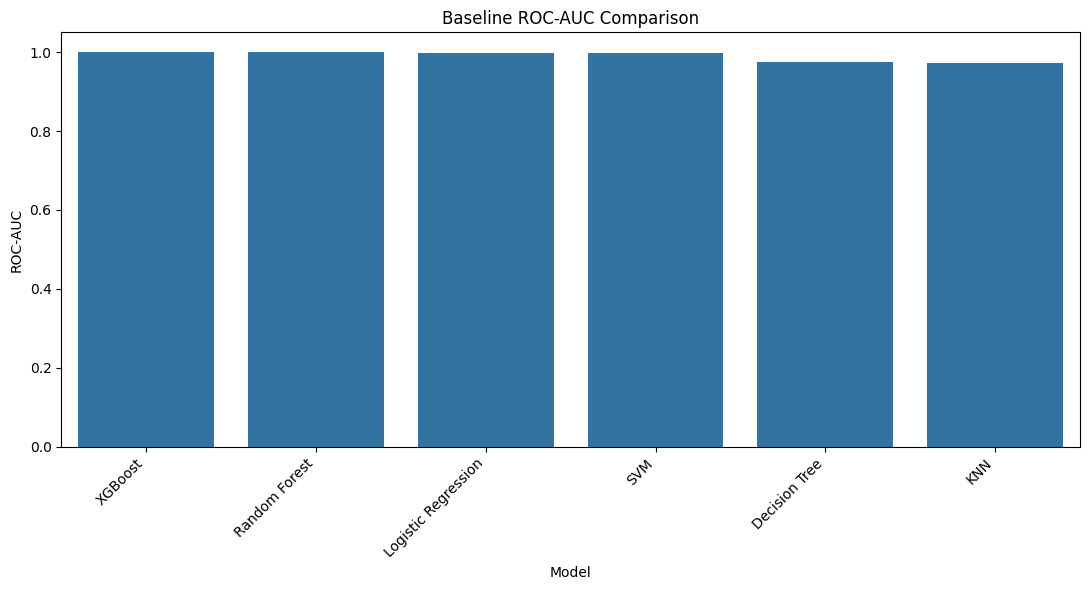

In [12]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=baseline_df,
    x="Model",
    y="ROC_AUC"
)

plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.05)
plt.title("Baseline ROC-AUC Comparison")
plt.xlabel("Model")
plt.ylabel("ROC-AUC")
plt.tight_layout()
plt.show()

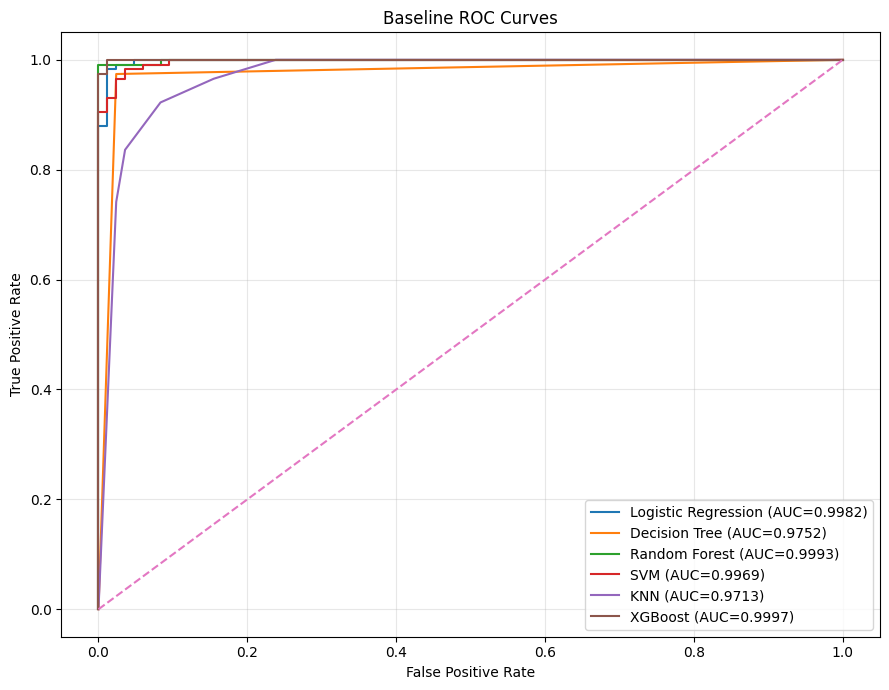

In [13]:
plt.figure(figsize=(9, 7))

for name in models.keys():

    y_prob = baseline_predictions[name]["y_prob"]

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Baseline ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

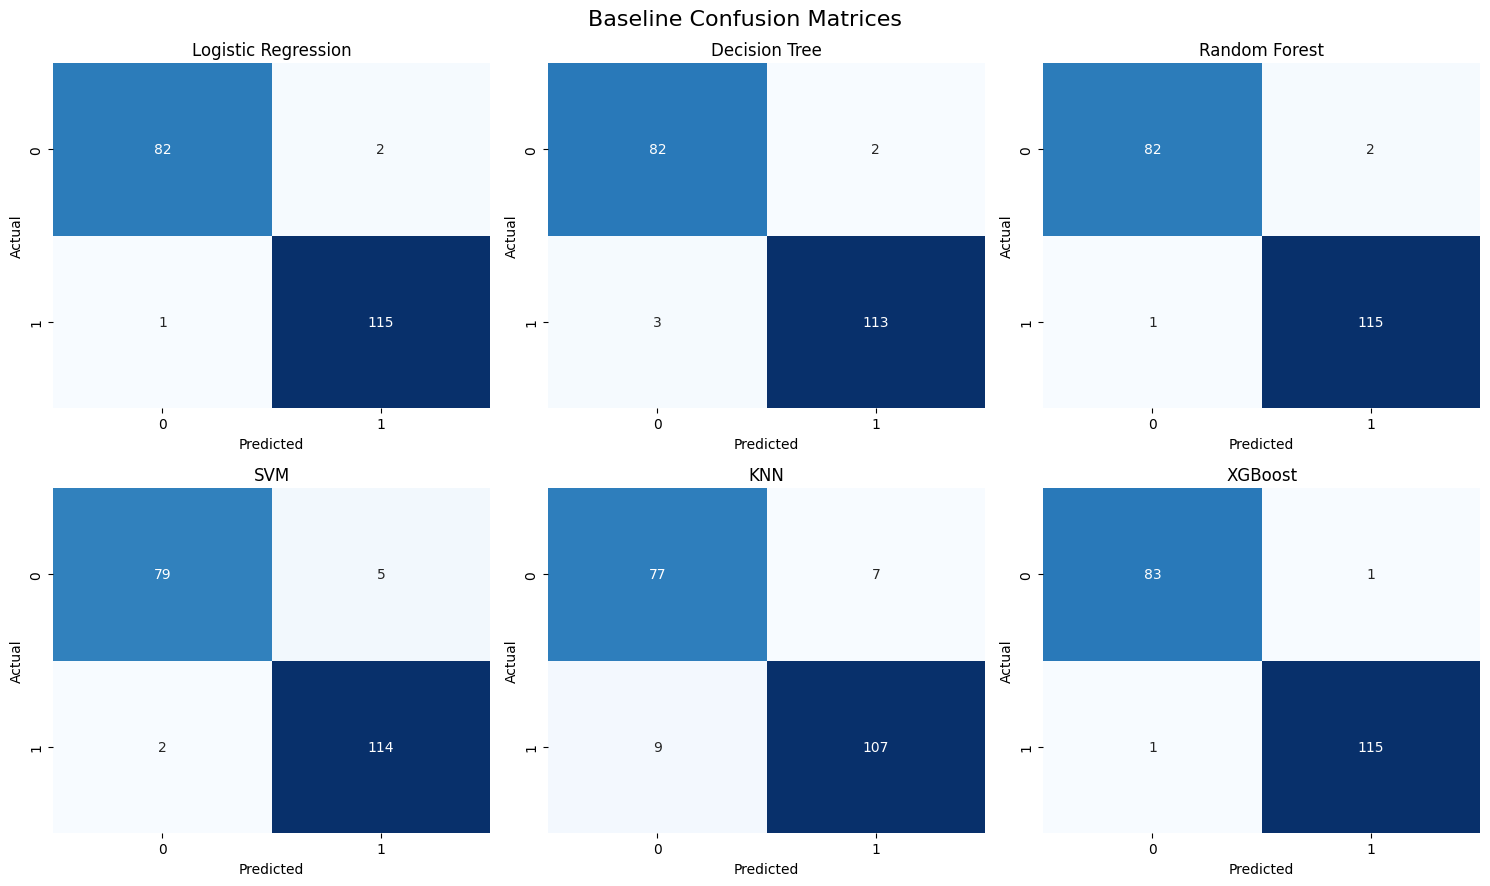

In [14]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

axes = axes.flatten()

for ax, name in zip(axes, models.keys()):

    y_pred = baseline_predictions[name]["y_pred"]

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Baseline Confusion Matrices", fontsize=16)
plt.tight_layout()
plt.show()

In [15]:
MEASUREMENT_LEVELS = [0.00, 0.05, 0.10, 0.15, 0.20]
MISSINGNESS_LEVELS = [0.00, 0.05, 0.10, 0.15, 0.20]
LABEL_NOISE_LEVELS = [0.00, 0.05, 0.10, 0.15, 0.20]

N_REPEATS = 10

print("Measurement levels:", MEASUREMENT_LEVELS)
print("Missingness levels:", MISSINGNESS_LEVELS)
print("Label-noise levels:", LABEL_NOISE_LEVELS)
print("Repetitions:", N_REPEATS)

Measurement levels: [0.0, 0.05, 0.1, 0.15, 0.2]
Missingness levels: [0.0, 0.05, 0.1, 0.15, 0.2]
Label-noise levels: [0.0, 0.05, 0.1, 0.15, 0.2]
Repetitions: 10


In [16]:
binary_features = [
    "gender",
    "fastingbloodsugar",
    "exerciseangia"
]

categorical_features = [
    "chestpain",
    "restingrelectro",
    "slope",
    "thal"
]

continuous_features = [
    "age",
    "restingBP",
    "serumcholestrol",
    "maxheartrate",
    "oldpeak",
    "noofmajorvessels"
]

# Keep only columns actually present
binary_features = [c for c in binary_features if c in X.columns]
categorical_features = [c for c in categorical_features if c in X.columns]
continuous_features = [c for c in continuous_features if c in X.columns]

print("Continuous:", continuous_features)
print("Binary:", binary_features)
print("Categorical/ordinal:", categorical_features)

Continuous: ['age', 'restingBP', 'serumcholestrol', 'maxheartrate', 'oldpeak', 'noofmajorvessels']
Binary: ['gender', 'fastingbloodsugar', 'exerciseangia']
Categorical/ordinal: ['chestpain', 'restingrelectro', 'slope']


In [17]:
def apply_measurement_stress(
    X_input,
    severity,
    random_state=42
):
    """
    Adds controlled Gaussian measurement noise to continuous features.

    severity:
        0.00 = no perturbation
        0.05 = approximately 5% relative noise
        ...
    """

    rng = np.random.default_rng(random_state)

    X_stressed = X_input.copy().reset_index(drop=True)

    for col in continuous_features:

        values = X_stressed[col].astype(float).values

        scale = np.std(values)

        if scale == 0:
            scale = 1.0

        noise = rng.normal(
            loc=0,
            scale=severity * scale,
            size=len(values)
        )

        X_stressed[col] = values + noise

    # Keep clinically bounded variables inside observed dataset range
    for col in continuous_features:

        lower = X[col].min()
        upper = X[col].max()

        X_stressed[col] = X_stressed[col].clip(
            lower,
            upper
        )

    return X_stressed

In [18]:
def apply_missingness_stress(
    X_input,
    severity,
    random_state=42
):
    """
    Randomly masks feature values according to severity.

    Missing values are then imputed using the TRAINING
    medians to avoid information leakage.
    """

    rng = np.random.default_rng(random_state)

    X_stressed = X_input.copy().reset_index(drop=True)

    if severity == 0:
        return X_stressed

    feature_names = list(X_stressed.columns)

    mask = rng.random(
        X_stressed.shape
    ) < severity

    for j, col in enumerate(feature_names):

        X_stressed.loc[
            mask[:, j],
            col
        ] = np.nan

    return X_stressed

In [19]:
def impute_using_train_medians(
    X_train,
    X_test
):

    X_train_new = X_train.copy()
    X_test_new = X_test.copy()

    medians = X_train_new.median(numeric_only=True)

    X_train_new = X_train_new.fillna(medians)
    X_test_new = X_test_new.fillna(medians)

    return X_train_new, X_test_new

In [20]:
def apply_label_noise(
    y_input,
    severity,
    random_state=42
):
    """
    Randomly flips binary training labels.
    """

    rng = np.random.default_rng(random_state)

    y_noisy = np.asarray(y_input).copy()

    if severity == 0:
        return pd.Series(
            y_noisy,
            index=y_input.index
        )

    n_flip = int(
        round(len(y_noisy) * severity)
    )

    if n_flip > 0:

        indices = rng.choice(
            len(y_noisy),
            size=n_flip,
            replace=False
        )

        y_noisy[indices] = 1 - y_noisy[indices]

    return pd.Series(
        y_noisy,
        index=y_input.index
    )

In [21]:
def evaluate_under_stress(
    model_dict,
    X_train,
    y_train,
    X_test,
    y_test,
    stress_type,
    severity,
    repeat
):

    records = []

    seed = 1000 + repeat

    # ----------------------------
    # Measurement stress
    # ----------------------------

    if stress_type == "Measurement":

        X_train_stress = apply_measurement_stress(
            X_train,
            severity,
            random_state=seed
        )

        X_test_stress = apply_measurement_stress(
            X_test,
            severity,
            random_state=seed + 500
        )

        y_train_stress = y_train.copy()

    # ----------------------------
    # Missingness stress
    # ----------------------------

    elif stress_type == "Missingness":

        X_train_stress = apply_missingness_stress(
            X_train,
            severity,
            random_state=seed
        )

        X_test_stress = apply_missingness_stress(
            X_test,
            severity,
            random_state=seed + 500
        )

        X_train_stress, X_test_stress = impute_using_train_medians(
            X_train_stress,
            X_test_stress
        )

        y_train_stress = y_train.copy()

    # ----------------------------
    # Label noise
    # ----------------------------

    elif stress_type == "Label Noise":

        X_train_stress = X_train.copy()
        X_test_stress = X_test.copy()

        y_train_stress = apply_label_noise(
            y_train,
            severity,
            random_state=seed
        )

    else:
        raise ValueError(
            "Unknown stress type."
        )

    # ----------------------------
    # Evaluate every model
    # ----------------------------

    for name, original_model in model_dict.items():

        # Clone using sklearn
        from sklearn.base import clone

        model = clone(original_model)

        model.fit(
            X_train_stress,
            y_train_stress
        )

        y_pred = model.predict(
            X_test_stress
        )

        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(
                X_test_stress
            )[:, 1]
        else:
            y_prob = model.decision_function(
                X_test_stress
            )

        records.append({
            "Stress_Type": stress_type,
            "Severity": severity,
            "Repeat": repeat,
            "Model": name,
            "Accuracy": accuracy_score(
                y_test,
                y_pred
            ),
            "Precision": precision_score(
                y_test,
                y_pred,
                zero_division=0
            ),
            "Recall": recall_score(
                y_test,
                y_pred,
                zero_division=0
            ),
            "F1": f1_score(
                y_test,
                y_pred,
                zero_division=0
            ),
            "ROC_AUC": roc_auc_score(
                y_test,
                y_prob
            ),
            "PR_AUC": average_precision_score(
                y_test,
                y_prob
            ),
            "MCC": matthews_corrcoef(
                y_test,
                y_pred
            )
        })

    return pd.DataFrame(records)

In [22]:
all_results = []

print("Running MEASUREMENT stress...")

for severity in MEASUREMENT_LEVELS:

    for repeat in range(N_REPEATS):

        result = evaluate_under_stress(
            models,
            X_train_raw,
            y_train,
            X_test_raw,
            y_test,
            stress_type="Measurement",
            severity=severity,
            repeat=repeat
        )

        all_results.append(result)

    print(
        f"Measurement severity {severity:.2f} completed."
    )

measurement_results = pd.concat(
    all_results,
    ignore_index=True
)

print("\nMeasurement stress completed.")
display(measurement_results.head())

Running MEASUREMENT stress...
Measurement severity 0.00 completed.
Measurement severity 0.05 completed.
Measurement severity 0.10 completed.
Measurement severity 0.15 completed.
Measurement severity 0.20 completed.

Measurement stress completed.


,Stress_Type,Severity,Repeat,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC
0,Measurement,0.0,0,Logistic Regression,0.985,0.982906,0.991379,0.987124,0.998153,0.998620,0.969212
1,Measurement,0.0,0,Decision Tree,0.975,0.982609,0.974138,0.978355,0.975164,0.972196,0.948820
2,Measurement,0.0,0,Random Forest,0.985,0.982906,0.991379,0.987124,0.999282,0.999509,0.969212
3,Measurement,0.0,0,SVM,0.965,0.957983,0.982759,0.970213,0.996921,0.997788,0.928250
4,Measurement,0.0,0,KNN,0.920,0.938596,0.922414,0.930435,0.971316,0.965458,0.836509


In [23]:
missing_results_list = []

print("Running MISSINGNESS stress...")

for severity in MISSINGNESS_LEVELS:

    for repeat in range(N_REPEATS):

        result = evaluate_under_stress(
            models,
            X_train_raw,
            y_train,
            X_test_raw,
            y_test,
            stress_type="Missingness",
            severity=severity,
            repeat=repeat
        )

        missing_results_list.append(result)

    print(
        f"Missingness severity {severity:.2f} completed."
    )

missingness_results = pd.concat(
    missing_results_list,
    ignore_index=True
)

print("\nMissingness stress completed.")
display(missingness_results.head())

Running MISSINGNESS stress...
Missingness severity 0.00 completed.
Missingness severity 0.05 completed.
Missingness severity 0.10 completed.
Missingness severity 0.15 completed.
Missingness severity 0.20 completed.

Missingness stress completed.


,Stress_Type,Severity,Repeat,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC
0,Missingness,0.0,0,Logistic Regression,0.985,0.982906,0.991379,0.987124,0.998153,0.998620,0.969212
1,Missingness,0.0,0,Decision Tree,0.975,0.982609,0.974138,0.978355,0.975164,0.972196,0.948820
2,Missingness,0.0,0,Random Forest,0.985,0.982906,0.991379,0.987124,0.999282,0.999509,0.969212
3,Missingness,0.0,0,SVM,0.965,0.957983,0.982759,0.970213,0.996921,0.997788,0.928250
4,Missingness,0.0,0,KNN,0.920,0.938596,0.922414,0.930435,0.971316,0.965458,0.836509


In [24]:
label_results_list = []

print("Running LABEL-NOISE stress...")

for severity in LABEL_NOISE_LEVELS:

    for repeat in range(N_REPEATS):

        result = evaluate_under_stress(
            models,
            X_train_raw,
            y_train,
            X_test_raw,
            y_test,
            stress_type="Label Noise",
            severity=severity,
            repeat=repeat
        )

        label_results_list.append(result)

    print(
        f"Label-noise severity {severity:.2f} completed."
    )

label_noise_results = pd.concat(
    label_results_list,
    ignore_index=True
)

print("\nLabel-noise stress completed.")
display(label_noise_results.head())

Running LABEL-NOISE stress...
Label-noise severity 0.00 completed.
Label-noise severity 0.05 completed.
Label-noise severity 0.10 completed.
Label-noise severity 0.15 completed.
Label-noise severity 0.20 completed.

Label-noise stress completed.


,Stress_Type,Severity,Repeat,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC
0,Label Noise,0.0,0,Logistic Regression,0.985,0.982906,0.991379,0.987124,0.998153,0.998620,0.969212
1,Label Noise,0.0,0,Decision Tree,0.975,0.982609,0.974138,0.978355,0.975164,0.972196,0.948820
2,Label Noise,0.0,0,Random Forest,0.985,0.982906,0.991379,0.987124,0.999282,0.999509,0.969212
3,Label Noise,0.0,0,SVM,0.965,0.957983,0.982759,0.970213,0.996921,0.997788,0.928250
4,Label Noise,0.0,0,KNN,0.920,0.938596,0.922414,0.930435,0.971316,0.965458,0.836509


In [25]:
stress_results = pd.concat(
    [
        measurement_results,
        missingness_results,
        label_noise_results
    ],
    ignore_index=True
)

print(
    "Total stress-test observations:",
    len(stress_results)
)

display(
    stress_results.head()
)

Total stress-test observations: 900


,Stress_Type,Severity,Repeat,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC
0,Measurement,0.0,0,Logistic Regression,0.985,0.982906,0.991379,0.987124,0.998153,0.998620,0.969212
1,Measurement,0.0,0,Decision Tree,0.975,0.982609,0.974138,0.978355,0.975164,0.972196,0.948820
2,Measurement,0.0,0,Random Forest,0.985,0.982906,0.991379,0.987124,0.999282,0.999509,0.969212
3,Measurement,0.0,0,SVM,0.965,0.957983,0.982759,0.970213,0.996921,0.997788,0.928250
4,Measurement,0.0,0,KNN,0.920,0.938596,0.922414,0.930435,0.971316,0.965458,0.836509


In [26]:
stress_summary = (
    stress_results
    .groupby(
        [
            "Stress_Type",
            "Severity",
            "Model"
        ]
    )
    .agg(
        Accuracy_Mean=("Accuracy", "mean"),
        Accuracy_SD=("Accuracy", "std"),
        F1_Mean=("F1", "mean"),
        F1_SD=("F1", "std"),
        ROC_AUC_Mean=("ROC_AUC", "mean"),
        ROC_AUC_SD=("ROC_AUC", "std"),
        PR_AUC_Mean=("PR_AUC", "mean"),
        MCC_Mean=("MCC", "mean")
    )
    .reset_index()
)

print("Stress summary:")
display(
    stress_summary.round(4)
)

Stress summary:


,Stress_Type,Severity,Model,Accuracy_Mean,Accuracy_SD,F1_Mean,F1_SD,ROC_AUC_Mean,ROC_AUC_SD,PR_AUC_Mean,MCC_Mean
0,Label Noise,0.0,Decision Tree,0.9750,0.0000,0.9784,0.0000,0.9752,0.0000,0.9722,0.9488
1,Label Noise,0.0,KNN,0.9200,0.0000,0.9304,0.0000,0.9713,0.0000,0.9655,0.8365
2,Label Noise,0.0,Logistic Regression,0.9850,0.0000,0.9871,0.0000,0.9982,0.0000,0.9986,0.9692
3,Label Noise,0.0,Random Forest,0.9850,0.0000,0.9871,0.0000,0.9993,0.0000,0.9995,0.9692
4,Label Noise,0.0,SVM,0.9650,0.0000,0.9702,0.0000,0.9969,0.0000,0.9978,0.9282
...,...,...,...,...,...,...,...,...,...,...,...
85,Missingness,0.2,KNN,0.8995,0.0205,0.9146,0.0169,0.9528,0.0092,0.9510,0.7937
86,Missingness,0.2,Logistic Regression,0.9185,0.0197,0.9312,0.0161,0.9735,0.0090,0.9792,0.8331
87,Missingness,0.2,Random Forest,0.9495,0.0179,0.9569,0.0150,0.9857,0.0085,0.9888,0.8965
88,Missingness,0.2,SVM,0.9245,0.0152,0.9357,0.0128,0.9789,0.0073,0.9837,0.8450


In [27]:
baseline_lookup = baseline_df.set_index("Model")

stress_summary["Baseline_ROC_AUC"] = (
    stress_summary["Model"]
    .map(baseline_lookup["ROC_AUC"])
)

stress_summary["AUC_Degradation"] = (
    stress_summary["Baseline_ROC_AUC"]
    - stress_summary["ROC_AUC_Mean"]
)

stress_summary["Relative_AUC_Degradation_%"] = (
    stress_summary["AUC_Degradation"]
    / stress_summary["Baseline_ROC_AUC"]
) * 100

stress_summary["Baseline_F1"] = (
    stress_summary["Model"]
    .map(baseline_lookup["F1"])
)

stress_summary["F1_Degradation"] = (
    stress_summary["Baseline_F1"]
    - stress_summary["F1_Mean"]
)

stress_summary["Relative_F1_Degradation_%"] = (
    stress_summary["F1_Degradation"]
    / stress_summary["Baseline_F1"].replace(0, np.nan)
) * 100

display(
    stress_summary.round(4)
)

,Stress_Type,Severity,Model,Accuracy_Mean,Accuracy_SD,F1_Mean,F1_SD,ROC_AUC_Mean,ROC_AUC_SD,PR_AUC_Mean,MCC_Mean,Baseline_ROC_AUC,AUC_Degradation,Relative_AUC_Degradation_%,Baseline_F1,F1_Degradation,Relative_F1_Degradation_%
0,Label Noise,0.0,Decision Tree,0.9750,0.0000,0.9784,0.0000,0.9752,0.0000,0.9722,0.9488,0.9752,-0.0000,-0.0000,0.9784,-0.0000,-0.0000
1,Label Noise,0.0,KNN,0.9200,0.0000,0.9304,0.0000,0.9713,0.0000,0.9655,0.8365,0.9713,0.0000,0.0000,0.9304,-0.0000,-0.0000
2,Label Noise,0.0,Logistic Regression,0.9850,0.0000,0.9871,0.0000,0.9982,0.0000,0.9986,0.9692,0.9982,0.0000,0.0000,0.9871,0.0000,0.0000
3,Label Noise,0.0,Random Forest,0.9850,0.0000,0.9871,0.0000,0.9993,0.0000,0.9995,0.9692,0.9993,0.0000,0.0000,0.9871,0.0000,0.0000
4,Label Noise,0.0,SVM,0.9650,0.0000,0.9702,0.0000,0.9969,0.0000,0.9978,0.9282,0.9969,-0.0000,-0.0000,0.9702,0.0000,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,Missingness,0.2,KNN,0.8995,0.0205,0.9146,0.0169,0.9528,0.0092,0.9510,0.7937,0.9713,0.0186,1.9114,0.9304,0.0158,1.7000
86,Missingness,0.2,Logistic Regression,0.9185,0.0197,0.9312,0.0161,0.9735,0.0090,0.9792,0.8331,0.9982,0.0246,2.4656,0.9871,0.0559,5.6678
87,Missingness,0.2,Random Forest,0.9495,0.0179,0.9569,0.0150,0.9857,0.0085,0.9888,0.8965,0.9993,0.0136,1.3592,0.9871,0.0302,3.0626
88,Missingness,0.2,SVM,0.9245,0.0152,0.9357,0.0128,0.9789,0.0073,0.9837,0.8450,0.9969,0.0180,1.8087,0.9702,0.0345,3.5537


In [28]:
stress_summary["Integrity_Score"] = (
    100
    * stress_summary["ROC_AUC_Mean"]
    / stress_summary["Baseline_ROC_AUC"]
)

stress_summary["Integrity_Score"] = (
    stress_summary["Integrity_Score"]
    .clip(lower=0, upper=100)
)

display(
    stress_summary[
        [
            "Stress_Type",
            "Severity",
            "Model",
            "Integrity_Score",
            "ROC_AUC_Mean",
            "Relative_AUC_Degradation_%"
        ]
    ].round(4)
)

,Stress_Type,Severity,Model,Integrity_Score,ROC_AUC_Mean,Relative_AUC_Degradation_%
0,Label Noise,0.0,Decision Tree,100.0000,0.9752,-0.0000
1,Label Noise,0.0,KNN,100.0000,0.9713,0.0000
2,Label Noise,0.0,Logistic Regression,100.0000,0.9982,0.0000
3,Label Noise,0.0,Random Forest,100.0000,0.9993,0.0000
4,Label Noise,0.0,SVM,100.0000,0.9969,-0.0000
...,...,...,...,...,...,...
85,Missingness,0.2,KNN,98.0886,0.9528,1.9114
86,Missingness,0.2,Logistic Regression,97.5344,0.9735,2.4656
87,Missingness,0.2,Random Forest,98.6408,0.9857,1.3592
88,Missingness,0.2,SVM,98.1913,0.9789,1.8087


In [29]:
overall_integrity = (
    stress_summary
    .groupby("Model")
    .agg(
        Mean_Integrity_Score=(
            "Integrity_Score",
            "mean"
        ),
        Worst_Integrity_Score=(
            "Integrity_Score",
            "min"
        ),
        Mean_AUC_Degradation=(
            "AUC_Degradation",
            "mean"
        ),
        Worst_AUC_Degradation=(
            "AUC_Degradation",
            "max"
        )
    )
    .reset_index()
)

overall_integrity = overall_integrity.sort_values(
    "Mean_Integrity_Score",
    ascending=False
).reset_index(drop=True)

print("OVERALL CHD-MIST MODEL INTEGRITY")
display(
    overall_integrity.round(4)
)

OVERALL CHD-MIST MODEL INTEGRITY


,Model,Mean_Integrity_Score,Worst_Integrity_Score,Mean_AUC_Degradation,Worst_AUC_Degradation
0,Random Forest,99.7355,98.6408,0.0026,0.0136
1,XGBoost,99.6514,98.3369,0.0035,0.0166
2,SVM,99.6000,98.1913,0.0040,0.0180
3,Logistic Regression,99.4739,97.5344,0.0052,0.0246
4,KNN,98.9211,93.6019,0.0094,0.0621
5,Decision Tree,94.1767,75.7314,0.0568,0.2367


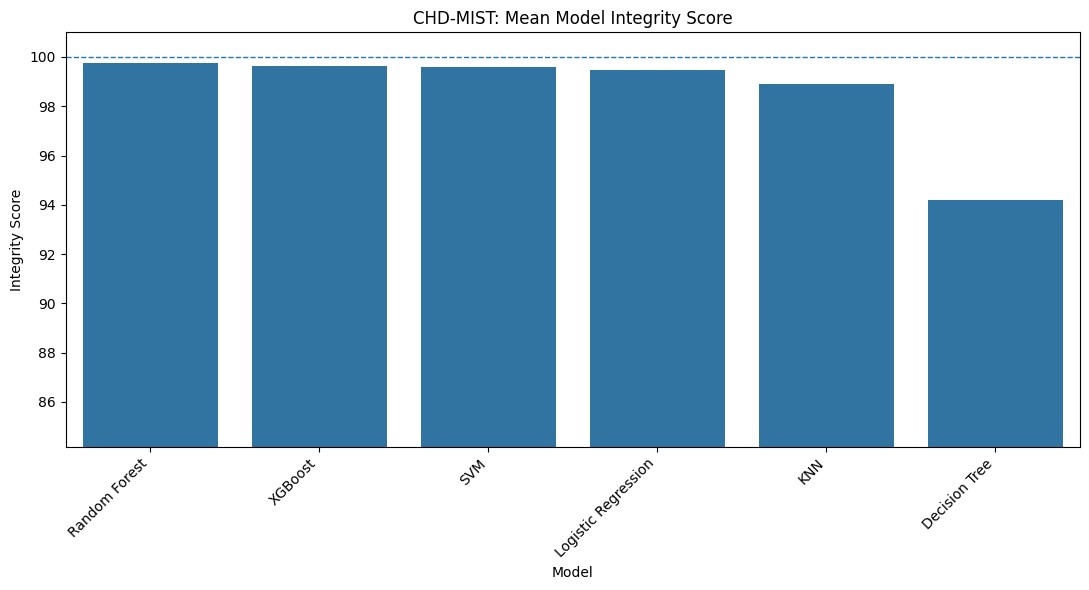

In [30]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=overall_integrity,
    x="Model",
    y="Mean_Integrity_Score"
)

plt.axhline(
    100,
    linestyle="--",
    linewidth=1
)

plt.xticks(rotation=45, ha="right")
plt.ylim(
    max(0, overall_integrity["Mean_Integrity_Score"].min() - 10),
    101
)

plt.title(
    "CHD-MIST: Mean Model Integrity Score"
)

plt.xlabel("Model")
plt.ylabel("Integrity Score")

plt.tight_layout()
plt.show()

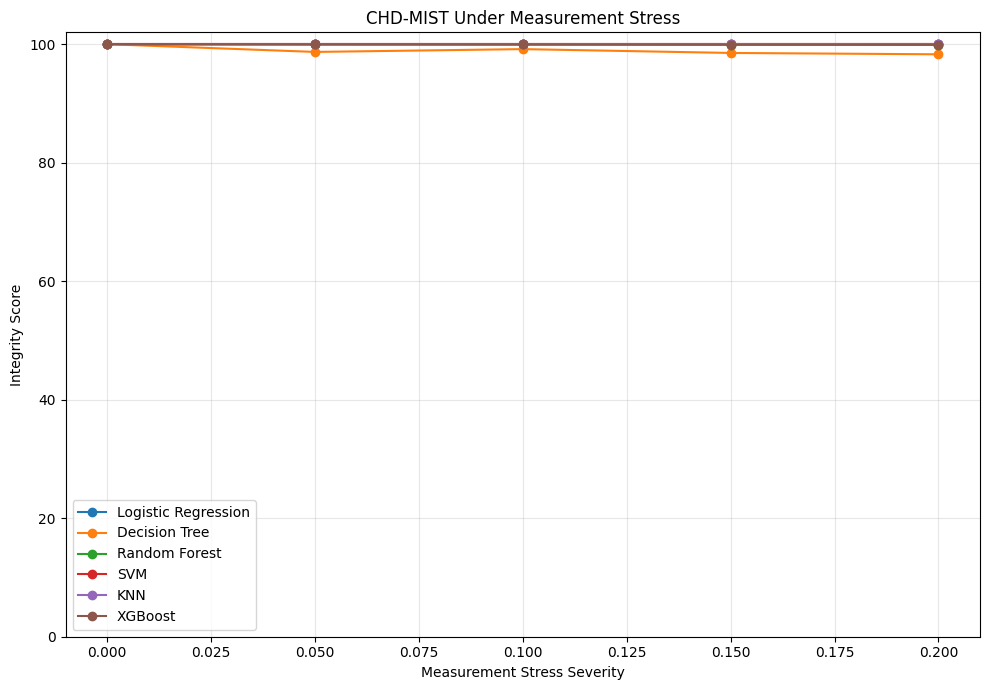

In [31]:
plt.figure(figsize=(10, 7))

for model_name in models.keys():

    subset = stress_summary[
        (stress_summary["Stress_Type"] == "Measurement") &
        (stress_summary["Model"] == model_name)
    ]

    plt.plot(
        subset["Severity"],
        subset["Integrity_Score"],
        marker="o",
        label=model_name
    )

plt.xlabel("Measurement Stress Severity")
plt.ylabel("Integrity Score")
plt.title(
    "CHD-MIST Under Measurement Stress"
)

plt.ylim(0, 102)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

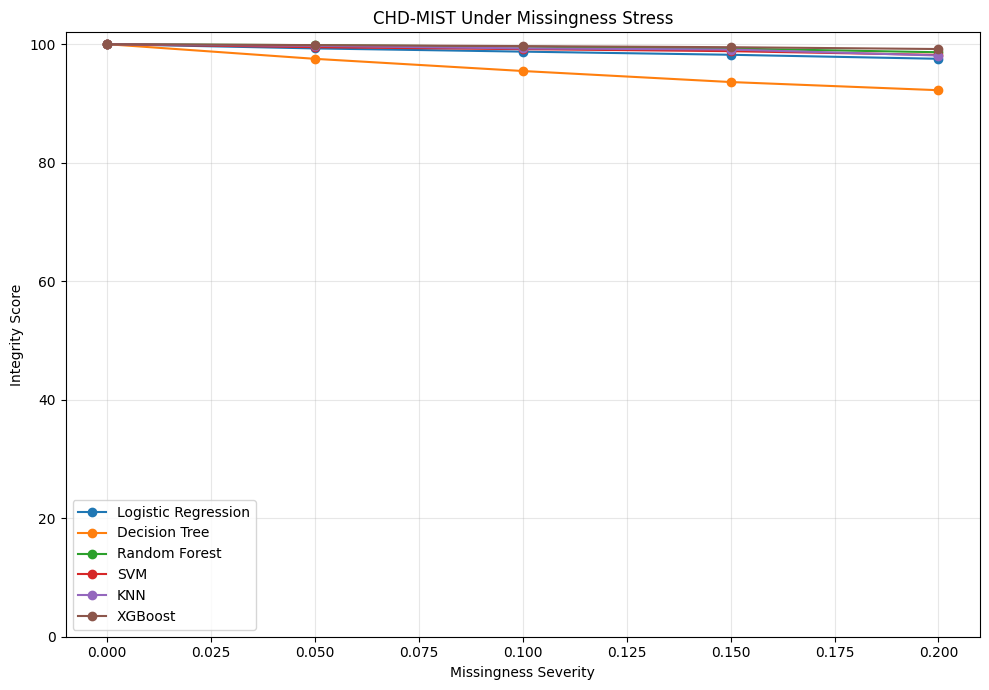

In [32]:
plt.figure(figsize=(10, 7))

for model_name in models.keys():

    subset = stress_summary[
        (stress_summary["Stress_Type"] == "Missingness") &
        (stress_summary["Model"] == model_name)
    ]

    plt.plot(
        subset["Severity"],
        subset["Integrity_Score"],
        marker="o",
        label=model_name
    )

plt.xlabel("Missingness Severity")
plt.ylabel("Integrity Score")
plt.title(
    "CHD-MIST Under Missingness Stress"
)

plt.ylim(0, 102)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

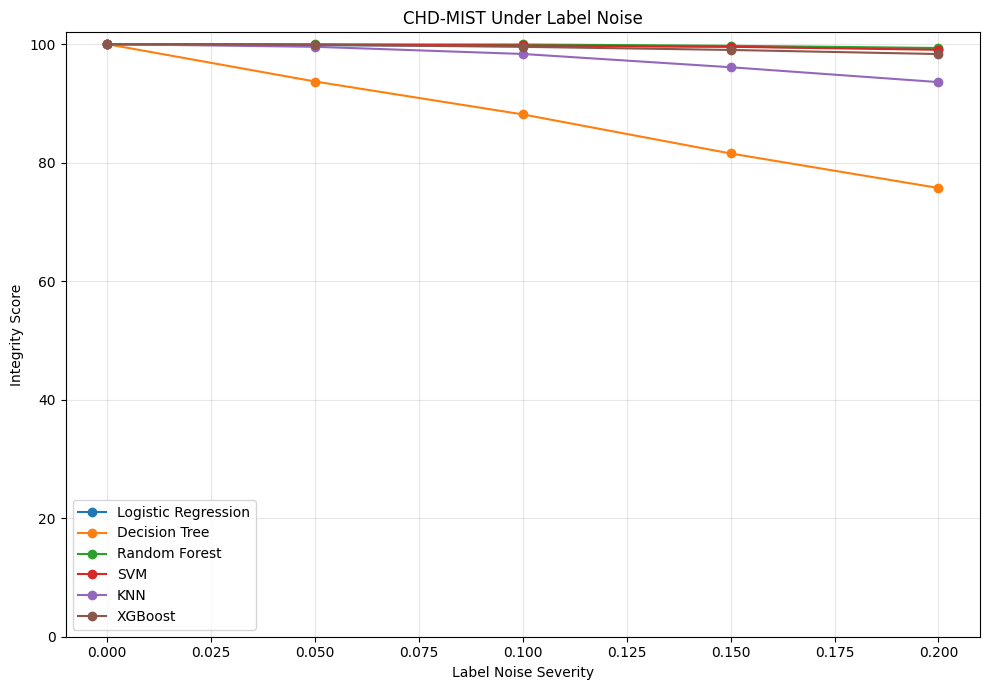

In [33]:
plt.figure(figsize=(10, 7))

for model_name in models.keys():

    subset = stress_summary[
        (stress_summary["Stress_Type"] == "Label Noise") &
        (stress_summary["Model"] == model_name)
    ]

    plt.plot(
        subset["Severity"],
        subset["Integrity_Score"],
        marker="o",
        label=model_name
    )

plt.xlabel("Label Noise Severity")
plt.ylabel("Integrity Score")
plt.title(
    "CHD-MIST Under Label Noise"
)

plt.ylim(0, 102)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

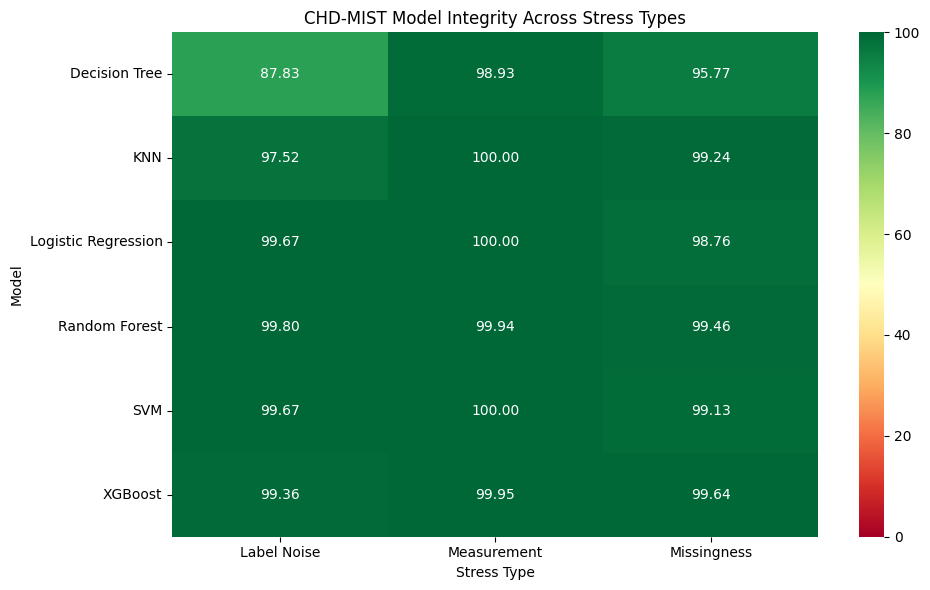

In [34]:
heatmap_data = (
    stress_summary
    .groupby(
        ["Model", "Stress_Type"]
    )["Integrity_Score"]
    .mean()
    .reset_index()
)

heatmap_matrix = heatmap_data.pivot(
    index="Model",
    columns="Stress_Type",
    values="Integrity_Score"
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=0,
    vmax=100
)

plt.title(
    "CHD-MIST Model Integrity Across Stress Types"
)

plt.xlabel("Stress Type")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

In [35]:
CRITICAL_THRESHOLD = 95.0

critical_rows = []

for stress_type in stress_summary["Stress_Type"].unique():

    for model_name in models.keys():

        subset = stress_summary[
            (stress_summary["Stress_Type"] == stress_type) &
            (stress_summary["Model"] == model_name)
        ].sort_values("Severity")

        critical = subset[
            subset["Integrity_Score"] < CRITICAL_THRESHOLD
        ]

        if len(critical) > 0:

            first_critical = critical.iloc[0]

            critical_severity = first_critical[
                "Severity"
            ]

        else:

            critical_severity = np.nan

        critical_rows.append({
            "Stress_Type": stress_type,
            "Model": model_name,
            "Critical_Severity": critical_severity
        })

critical_stress_df = pd.DataFrame(
    critical_rows
)

print(
    f"Critical stress threshold = {CRITICAL_THRESHOLD}%"
)

display(
    critical_stress_df
)

Critical stress threshold = 95.0%


,Stress_Type,Model,Critical_Severity
0,Label Noise,Logistic Regression,NaN
1,Label Noise,Decision Tree,0.05
2,Label Noise,Random Forest,NaN
3,Label Noise,SVM,NaN
4,Label Noise,KNN,0.20
5,Label Noise,XGBoost,NaN
6,Measurement,Logistic Regression,NaN
7,Measurement,Decision Tree,NaN
8,Measurement,Random Forest,NaN
9,Measurement,SVM,NaN


In [36]:
baseline_rank = (
    baseline_df
    .sort_values("ROC_AUC", ascending=False)
    [["Model", "ROC_AUC"]]
    .reset_index(drop=True)
)

baseline_rank["Baseline_Rank"] = (
    np.arange(len(baseline_rank)) + 1
)

print("Baseline ranking:")
display(baseline_rank)

Baseline ranking:


,Model,ROC_AUC,Baseline_Rank
0,XGBoost,0.999692,1
1,Random Forest,0.999282,2
2,Logistic Regression,0.998153,3
3,SVM,0.996921,4
4,Decision Tree,0.975164,5
5,KNN,0.971316,6


In [37]:
worst_case = (
    stress_summary
    .groupby("Model")
    ["Integrity_Score"]
    .min()
    .reset_index()
    .rename(
        columns={
            "Integrity_Score":
            "Worst_Integrity_Score"
        }
    )
    .sort_values(
        "Worst_Integrity_Score",
        ascending=False
    )
    .reset_index(drop=True)
)

worst_case["Worst_Stress_Rank"] = (
    np.arange(len(worst_case)) + 1
)

print("Worst-case integrity ranking:")
display(
    worst_case
)

Worst-case integrity ranking:


,Model,Worst_Integrity_Score,Worst_Stress_Rank
0,Random Forest,98.640752,1
1,XGBoost,98.336926,2
2,SVM,98.191270,3
3,Logistic Regression,97.534444,4
4,KNN,93.601881,5
5,Decision Tree,75.731425,6


In [38]:
statistical_results = []

models_list = list(models.keys())

for i in range(len(models_list)):

    for j in range(i + 1, len(models_list)):

        model_a = models_list[i]
        model_b = models_list[j]

        a = (
            stress_results[
                stress_results["Model"] == model_a
            ]
            .groupby(
                [
                    "Stress_Type",
                    "Severity",
                    "Repeat"
                ]
            )["ROC_AUC"]
            .mean()
        )

        b = (
            stress_results[
                stress_results["Model"] == model_b
            ]
            .groupby(
                [
                    "Stress_Type",
                    "Severity",
                    "Repeat"
                ]
            )["ROC_AUC"]
            .mean()
        )

        common = pd.concat(
            [a, b],
            axis=1,
            join="inner"
        ).dropna()

        if len(common) >= 5:

            try:

                stat, p = wilcoxon(
                    common.iloc[:, 0],
                    common.iloc[:, 1],
                    alternative="two-sided"
                )

            except Exception:

                stat = np.nan
                p = np.nan

        else:

            stat = np.nan
            p = np.nan

        statistical_results.append({
            "Model_A": model_a,
            "Model_B": model_b,
            "Wilcoxon_Statistic": stat,
            "P_Value": p
        })

pairwise_stats_df = pd.DataFrame(
    statistical_results
)

pairwise_stats_df["Significant_p<0.05"] = (
    pairwise_stats_df["P_Value"] < 0.05
)

display(
    pairwise_stats_df.round(6)
)

,Model_A,Model_B,Wilcoxon_Statistic,P_Value,Significant_p<0.05
0,Logistic Regression,Decision Tree,0.0,0.000000,True
1,Logistic Regression,Random Forest,290.5,0.000000,True
2,Logistic Regression,SVM,4404.5,0.033565,True
3,Logistic Regression,KNN,0.0,0.000000,True
4,Logistic Regression,XGBoost,2188.0,0.000000,True
5,Decision Tree,Random Forest,0.0,0.000000,True
6,Decision Tree,SVM,0.0,0.000000,True
7,Decision Tree,KNN,917.0,0.000000,True
8,Decision Tree,XGBoost,0.0,0.000000,True
9,Random Forest,SVM,98.0,0.000000,True


In [39]:
friedman_results = []

for stress_type in stress_results["Stress_Type"].unique():

    subset = stress_results[
        stress_results["Stress_Type"] == stress_type
    ]

    pivot = subset.pivot_table(
        index=["Severity", "Repeat"],
        columns="Model",
        values="ROC_AUC",
        aggfunc="mean"
    ).dropna()

    if pivot.shape[0] >= 3:

        arrays = [
            pivot[m].values
            for m in models_list
        ]

        try:

            stat, p = friedmanchisquare(
                *arrays
            )

        except Exception:

            stat = np.nan
            p = np.nan

    else:

        stat = np.nan
        p = np.nan

    friedman_results.append({
        "Stress_Type": stress_type,
        "Friedman_Statistic": stat,
        "P_Value": p
    })

friedman_df = pd.DataFrame(
    friedman_results
)

display(
    friedman_df.round(6)
)

,Stress_Type,Friedman_Statistic,P_Value
0,Measurement,227.723368,0.0
1,Missingness,236.777143,0.0
2,Label Noise,203.769319,0.0


In [40]:
final_summary = (
    baseline_df[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "PR_AUC",
            "MCC"
        ]
    ]
    .merge(
        overall_integrity[
            [
                "Model",
                "Mean_Integrity_Score",
                "Worst_Integrity_Score",
                "Mean_AUC_Degradation",
                "Worst_AUC_Degradation"
            ]
        ],
        on="Model"
    )
)

final_summary = final_summary.sort_values(
    "Mean_Integrity_Score",
    ascending=False
).reset_index(drop=True)

print("FINAL CHD-MIST SUMMARY")
display(
    final_summary.round(4)
)

FINAL CHD-MIST SUMMARY


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC,Mean_Integrity_Score,Worst_Integrity_Score,Mean_AUC_Degradation,Worst_AUC_Degradation
0,Random Forest,0.985,0.9829,0.9914,0.9871,0.9993,0.9995,0.9692,99.7355,98.6408,0.0026,0.0136
1,XGBoost,0.990,0.9914,0.9914,0.9914,0.9997,0.9998,0.9795,99.6514,98.3369,0.0035,0.0166
2,SVM,0.965,0.9580,0.9828,0.9702,0.9969,0.9978,0.9282,99.6000,98.1913,0.0040,0.0180
3,Logistic Regression,0.985,0.9829,0.9914,0.9871,0.9982,0.9986,0.9692,99.4739,97.5344,0.0052,0.0246
4,KNN,0.920,0.9386,0.9224,0.9304,0.9713,0.9655,0.8365,98.9211,93.6019,0.0094,0.0621
5,Decision Tree,0.975,0.9826,0.9741,0.9784,0.9752,0.9722,0.9488,94.1767,75.7314,0.0568,0.2367


In [41]:
best_baseline_model = (
    baseline_df
    .sort_values(
        "ROC_AUC",
        ascending=False
    )
    .iloc[0]["Model"]
)

most_robust_model = (
    overall_integrity
    .sort_values(
        "Mean_Integrity_Score",
        ascending=False
    )
    .iloc[0]["Model"]
)

print(
    "Best baseline model:",
    best_baseline_model
)

print(
    "Most robust model under CHD-MIST:",
    most_robust_model
)

if best_baseline_model != most_robust_model:

    print(
        "\nIMPORTANT RESULT:"
    )

    print(
        "The model with the highest clean-data "
        "performance is different from the model "
        "with the highest mean integrity."
    )

else:

    print(
        "\nThe best baseline model also has the "
        "highest mean integrity."
    )

Best baseline model: XGBoost
Most robust model under CHD-MIST: Random Forest

IMPORTANT RESULT:
The model with the highest clean-data performance is different from the model with the highest mean integrity.


In [42]:
OUTPUT_DIR = "CHD_MIST_Results"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

baseline_df.to_csv(
    f"{OUTPUT_DIR}/baseline_results.csv",
    index=False
)

stress_results.to_csv(
    f"{OUTPUT_DIR}/stress_results_all.csv",
    index=False
)

stress_summary.to_csv(
    f"{OUTPUT_DIR}/stress_summary.csv",
    index=False
)

overall_integrity.to_csv(
    f"{OUTPUT_DIR}/integrity_scores.csv",
    index=False
)

critical_stress_df.to_csv(
    f"{OUTPUT_DIR}/critical_stress.csv",
    index=False
)

pairwise_stats_df.to_csv(
    f"{OUTPUT_DIR}/pairwise_wilcoxon.csv",
    index=False
)

friedman_df.to_csv(
    f"{OUTPUT_DIR}/friedman_tests.csv",
    index=False
)

final_summary.to_csv(
    f"{OUTPUT_DIR}/final_summary.csv",
    index=False
)

print("All CSV files saved.")

All CSV files saved.


In [43]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "CHD_MIST_Results",
    "zip",
    OUTPUT_DIR
)

print("Created:", zip_path)

files.download(zip_path)

Created: /content/CHD_MIST_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# CHD-MIST Robustness Upgrade
The following cells provide the publication-oriented robustness analysis:
- bounded measurement perturbation (explicit absolute perturbation ranges, not claimed as clinical measurement-error estimates),
- MCAR and feature-dependent missingness,
- label noise,
- bootstrap confidence intervals,
- effect sizes,
- Benjamini-Hochberg correction,
- consolidated publication tables.

Run these cells after the baseline/model-definition cells above. They are designed to supersede the earlier stress-analysis cells when preparing the final manuscript.

In [44]:

# Publication-oriented CHD-MIST settings
from sklearn.base import clone
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os, shutil

RANDOM_SEED = 42
N_REPEATS_UPGRADED = 20

# Explicit bounded perturbations.
# IMPORTANT: these are controlled robustness perturbations, NOT claimed
# to represent empirically estimated clinical measurement-error distributions.
MEASUREMENT_DELTAS = {
    "restingBP":  [0, 3, 5, 8, 10],
    "serumcholestrol": [0, 5, 10, 15, 20],
    "maxheartrate": [0, 3, 5, 8, 10],
    "oldpeak": [0, 0.10, 0.25, 0.50, 0.75],
}

UPGRADED_LEVELS = [0.00, 0.05, 0.10, 0.15, 0.20]

print("Upgraded CHD-MIST configuration loaded.")
print("Repeats:", N_REPEATS_UPGRADED)


Upgraded CHD-MIST configuration loaded.
Repeats: 20


In [45]:

def bounded_measurement_stress(X_input, severity, random_state=42):
    """
    Controlled bounded measurement stress.
    Continuous variables are perturbed by a random signed amount whose
    maximum magnitude increases with severity. Values are clipped to
    the observed training-data range.

    This is a robustness experiment, not a claim about clinical
    measurement-error distributions.
    """
    rng = np.random.default_rng(random_state)
    X_out = X_input.copy().reset_index(drop=True)

    for col, deltas in MEASUREMENT_DELTAS.items():
        if col not in X_out.columns:
            continue

        level_idx = int(round(severity * 20))
        level_idx = min(level_idx, len(deltas) - 1)
        max_delta = deltas[level_idx]

        if max_delta == 0:
            continue

        signs = rng.choice([-1.0, 1.0], size=len(X_out))
        magnitudes = rng.uniform(0, max_delta, size=len(X_out))
        X_out[col] = X_out[col].astype(float) + signs * magnitudes

        # Preserve the observed support of the training data.
        X_out[col] = X_out[col].clip(
            X_train_raw[col].min(),
            X_train_raw[col].max()
        )

    return X_out


def mcar_missingness(X_input, severity, random_state=42):
    rng = np.random.default_rng(random_state)
    X_out = X_input.copy().reset_index(drop=True)

    if severity == 0:
        return X_out

    mask = rng.random(X_out.shape) < severity
    X_out = X_out.mask(mask)
    return X_out


def feature_dependent_missingness(X_input, severity, random_state=42):
    """
    Controlled feature-dependent missingness:
    high values of selected clinical variables have a higher probability
    of being masked. This is a stress scenario, not a claim about the
    true missing-data mechanism in clinical practice.
    """
    rng = np.random.default_rng(random_state)
    X_out = X_input.copy().reset_index(drop=True)

    if severity == 0:
        return X_out

    base = np.full(X_out.shape, severity, dtype=float)

    # Selected variables receive value-dependent missingness.
    for col in ["restingBP", "serumcholestrol", "oldpeak"]:
        if col in X_out.columns:
            values = X_out[col].astype(float).values
            vmin, vmax = np.nanmin(values), np.nanmax(values)
            scaled = (values - vmin) / (vmax - vmin + 1e-12)
            j = X_out.columns.get_loc(col)
            base[:, j] = severity * (0.5 + scaled)

    base = np.clip(base, 0, 1)
    mask = rng.random(X_out.shape) < base
    return X_out.mask(mask)


def impute_from_training_medians(X_train_in, X_test_in):
    medians = X_train_in.median(numeric_only=True)
    return (
        X_train_in.fillna(medians),
        X_test_in.fillna(medians)
    )


def flip_training_labels(y_input, severity, random_state=42):
    rng = np.random.default_rng(random_state)
    y_out = np.asarray(y_input).copy()

    n_flip = int(round(len(y_out) * severity))
    if n_flip > 0:
        idx = rng.choice(len(y_out), n_flip, replace=False)
        y_out[idx] = 1 - y_out[idx]

    return pd.Series(y_out, index=y_input.index)


In [46]:

def run_upgraded_stress(model_dict, stress_type, severity, repeat):
    seed = RANDOM_SEED + repeat * 100 + int(severity * 1000)

    Xtr = X_train_raw.copy()
    Xte = X_test_raw.copy()
    ytr = y_train.copy()

    if stress_type == "Measurement":
        Xtr = bounded_measurement_stress(Xtr, severity, seed)
        Xte = bounded_measurement_stress(Xte, severity, seed + 1)

    elif stress_type == "MCAR Missingness":
        Xtr = mcar_missingness(Xtr, severity, seed)
        Xte = mcar_missingness(Xte, severity, seed + 1)
        Xtr, Xte = impute_from_training_medians(Xtr, Xte)

    elif stress_type == "Feature-Dependent Missingness":
        Xtr = feature_dependent_missingness(Xtr, severity, seed)
        Xte = feature_dependent_missingness(Xte, severity, seed + 1)
        Xtr, Xte = impute_from_training_medians(Xtr, Xte)

    elif stress_type == "Label Noise":
        ytr = flip_training_labels(ytr, severity, seed)

    else:
        raise ValueError("Unknown stress type")

    rows = []

    for model_name, base_model in model_dict.items():
        model = clone(base_model)
        model.fit(Xtr, ytr)

        pred = model.predict(Xte)
        prob = model.predict_proba(Xte)[:, 1]

        rows.append({
            "Stress_Type": stress_type,
            "Severity": severity,
            "Repeat": repeat,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "ROC_AUC": roc_auc_score(y_test, prob),
            "PR_AUC": average_precision_score(y_test, prob),
            "MCC": matthews_corrcoef(y_test, pred)
        })

    return pd.DataFrame(rows)


In [47]:

# Run upgraded experiments
upgraded_parts = []

stress_types = [
    "Measurement",
    "MCAR Missingness",
    "Feature-Dependent Missingness",
    "Label Noise"
]

for stress_type in stress_types:
    print(f"\nRunning {stress_type} stress...")

    for severity in UPGRADED_LEVELS:
        for repeat in range(N_REPEATS_UPGRADED):
            upgraded_parts.append(
                run_upgraded_stress(
                    models,
                    stress_type,
                    severity,
                    repeat
                )
            )

        print(f"  severity={severity:.2f} complete")

upgraded_stress_results = pd.concat(
    upgraded_parts,
    ignore_index=True
)

print("\nUpgraded stress observations:", len(upgraded_stress_results))
display(upgraded_stress_results.head())



Running Measurement stress...
  severity=0.00 complete
  severity=0.05 complete
  severity=0.10 complete
  severity=0.15 complete
  severity=0.20 complete

Running MCAR Missingness stress...
  severity=0.00 complete
  severity=0.05 complete
  severity=0.10 complete
  severity=0.15 complete
  severity=0.20 complete

Running Feature-Dependent Missingness stress...
  severity=0.00 complete
  severity=0.05 complete
  severity=0.10 complete
  severity=0.15 complete
  severity=0.20 complete

Running Label Noise stress...
  severity=0.00 complete
  severity=0.05 complete
  severity=0.10 complete
  severity=0.15 complete
  severity=0.20 complete

Upgraded stress observations: 2400


,Stress_Type,Severity,Repeat,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC
0,Measurement,0.0,0,Logistic Regression,0.985,0.982906,0.991379,0.987124,0.998153,0.998620,0.969212
1,Measurement,0.0,0,Decision Tree,0.975,0.982609,0.974138,0.978355,0.975164,0.972196,0.948820
2,Measurement,0.0,0,Random Forest,0.985,0.982906,0.991379,0.987124,0.999282,0.999509,0.969212
3,Measurement,0.0,0,SVM,0.965,0.957983,0.982759,0.970213,0.996921,0.997788,0.928250
4,Measurement,0.0,0,KNN,0.920,0.938596,0.922414,0.930435,0.971316,0.965458,0.836509


In [48]:

# Summaries with 95% bootstrap confidence intervals
def bootstrap_ci(values, statistic=np.mean, n_boot=2000, seed=42):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return np.nan, np.nan

    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        boot[i] = statistic(sample)

    return np.percentile(boot, 2.5), np.percentile(boot, 97.5)


summary_rows = []

for (stype, severity, model_name), g in upgraded_stress_results.groupby(
    ["Stress_Type", "Severity", "Model"]
):
    mean_auc = g["ROC_AUC"].mean()
    sd_auc = g["ROC_AUC"].std(ddof=1)

    ci_low, ci_high = bootstrap_ci(
        g["ROC_AUC"].values,
        n_boot=2000,
        seed=RANDOM_SEED + int(severity * 1000)
    )

    baseline_auc = baseline_df.loc[
        baseline_df["Model"] == model_name,
        "ROC_AUC"
    ].iloc[0]

    integrity = 100 * mean_auc / baseline_auc
    degradation = baseline_auc - mean_auc

    summary_rows.append({
        "Stress_Type": stype,
        "Severity": severity,
        "Model": model_name,
        "ROC_AUC_Mean": mean_auc,
        "ROC_AUC_SD": sd_auc,
        "ROC_AUC_CI95_Low": ci_low,
        "ROC_AUC_CI95_High": ci_high,
        "Baseline_ROC_AUC": baseline_auc,
        "AUC_Degradation": degradation,
        "Relative_AUC_Degradation_%": 100 * degradation / baseline_auc,
        "Integrity_Score": np.clip(integrity, 0, 100)
    })

upgraded_summary = pd.DataFrame(summary_rows)

display(upgraded_summary.round(4))


,Stress_Type,Severity,Model,ROC_AUC_Mean,ROC_AUC_SD,ROC_AUC_CI95_Low,ROC_AUC_CI95_High,Baseline_ROC_AUC,AUC_Degradation,Relative_AUC_Degradation_%,Integrity_Score
0,Feature-Dependent Missingness,0.0,Decision Tree,0.9752,0.0000,0.9752,0.9752,0.9752,-0.0000,-0.0000,100.0000
1,Feature-Dependent Missingness,0.0,KNN,0.9713,0.0000,0.9713,0.9713,0.9713,0.0000,0.0000,100.0000
2,Feature-Dependent Missingness,0.0,Logistic Regression,0.9982,0.0000,0.9982,0.9982,0.9982,0.0000,0.0000,100.0000
3,Feature-Dependent Missingness,0.0,Random Forest,0.9993,0.0000,0.9993,0.9993,0.9993,-0.0000,-0.0000,100.0000
4,Feature-Dependent Missingness,0.0,SVM,0.9969,0.0000,0.9969,0.9969,0.9969,-0.0000,-0.0000,100.0000
...,...,...,...,...,...,...,...,...,...,...,...
115,Measurement,0.2,KNN,0.9745,0.0047,0.9726,0.9764,0.9713,-0.0032,-0.3270,100.0000
116,Measurement,0.2,Logistic Regression,0.9980,0.0004,0.9978,0.9982,0.9982,0.0001,0.0144,99.9856
117,Measurement,0.2,Random Forest,0.9986,0.0002,0.9985,0.9987,0.9993,0.0007,0.0668,99.9332
118,Measurement,0.2,SVM,0.9966,0.0004,0.9965,0.9968,0.9969,0.0003,0.0278,99.9722


In [49]:

# Overall integrity with confidence intervals
overall_rows = []

for model_name in models.keys():
    g = upgraded_stress_results[
        upgraded_stress_results["Model"] == model_name
    ].copy()

    baseline_auc = baseline_df.loc[
        baseline_df["Model"] == model_name,
        "ROC_AUC"
    ].iloc[0]

    integrity_values = 100 * g["ROC_AUC"].values / baseline_auc

    ci_low, ci_high = bootstrap_ci(
        integrity_values,
        n_boot=3000,
        seed=RANDOM_SEED
    )

    overall_rows.append({
        "Model": model_name,
        "Mean_Integrity_Score": np.mean(integrity_values),
        "Integrity_CI95_Low": ci_low,
        "Integrity_CI95_High": ci_high,
        "Worst_Integrity_Score": np.min(integrity_values),
        "Mean_AUC_Degradation": np.mean(
            baseline_auc - g["ROC_AUC"]
        )
    })

upgraded_overall = pd.DataFrame(overall_rows).sort_values(
    "Mean_Integrity_Score",
    ascending=False
).reset_index(drop=True)

display(upgraded_overall.round(4))


,Model,Mean_Integrity_Score,Integrity_CI95_Low,Integrity_CI95_High,Worst_Integrity_Score,Mean_AUC_Degradation
0,Random Forest,99.6400,99.5859,99.6918,97.3092,0.0036
1,XGBoost,99.6269,99.5738,99.6765,95.9450,0.0037
2,SVM,99.4799,99.4096,99.5488,97.0043,0.0052
3,Logistic Regression,99.2540,99.1555,99.3505,96.3603,0.0074
4,KNN,99.0672,98.9074,99.2251,92.1602,0.0091
5,Decision Tree,94.7189,94.0844,95.3389,71.1008,0.0515


In [50]:

# Effect size: paired degradation across matched stress conditions
effect_rows = []

condition_cols = ["Stress_Type", "Severity", "Repeat"]

for i, model_a in enumerate(models.keys()):
    for model_b in list(models.keys())[i+1:]:

        auc_a = (
            upgraded_stress_results[
                upgraded_stress_results["Model"] == model_a
            ]
            .set_index(condition_cols)["ROC_AUC"]
        )

        auc_b = (
            upgraded_stress_results[
                upgraded_stress_results["Model"] == model_b
            ]
            .set_index(condition_cols)["ROC_AUC"]
        )

        paired = pd.concat(
            [auc_a, auc_b],
            axis=1,
            join="inner"
        ).dropna()

        diff = paired.iloc[:, 0] - paired.iloc[:, 1]

        # Rank-biserial-style effect based on positive/negative differences.
        pos = np.sum(diff > 0)
        neg = np.sum(diff < 0)
        denom = pos + neg

        rank_biserial = (
            (pos - neg) / denom
            if denom > 0 else np.nan
        )

        try:
            stat, p = wilcoxon(
                paired.iloc[:, 0],
                paired.iloc[:, 1],
                alternative="two-sided"
            )
        except Exception:
            stat, p = np.nan, np.nan

        effect_rows.append({
            "Model_A": model_a,
            "Model_B": model_b,
            "N_Paired": len(paired),
            "Wilcoxon_Statistic": stat,
            "Raw_P": p,
            "Rank_Biserial_Effect": rank_biserial
        })

effect_df = pd.DataFrame(effect_rows)

# Multiple-comparison correction
valid = effect_df["Raw_P"].notna()

if valid.any():
    rejected, corrected_p, _, _ = multipletests(
        effect_df.loc[valid, "Raw_P"],
        alpha=0.05,
        method="fdr_bh"
    )

    effect_df.loc[valid, "FDR_Adjusted_P"] = corrected_p
    effect_df.loc[valid, "FDR_Significant"] = rejected

display(effect_df.round(6))


,Model_A,Model_B,N_Paired,Wilcoxon_Statistic,Raw_P,Rank_Biserial_Effect,FDR_Adjusted_P,FDR_Significant
0,Logistic Regression,Decision Tree,400,0.0,0.000000,1.000000,0.000000,True
1,Logistic Regression,Random Forest,400,1367.0,0.000000,-0.930000,0.000000,True
2,Logistic Regression,SVM,400,36282.5,0.116102,0.172932,0.116102,False
3,Logistic Regression,KNN,400,1.0,0.000000,0.995000,0.000000,True
4,Logistic Regression,XGBoost,400,8953.0,0.000000,-0.789474,0.000000,True
5,Decision Tree,Random Forest,400,0.0,0.000000,-1.000000,0.000000,True
6,Decision Tree,SVM,400,0.0,0.000000,-1.000000,0.000000,True
7,Decision Tree,KNN,400,7918.5,0.000000,-0.460000,0.000000,True
8,Decision Tree,XGBoost,400,0.0,0.000000,-1.000000,0.000000,True
9,Random Forest,SVM,400,327.5,0.000000,0.950000,0.000000,True


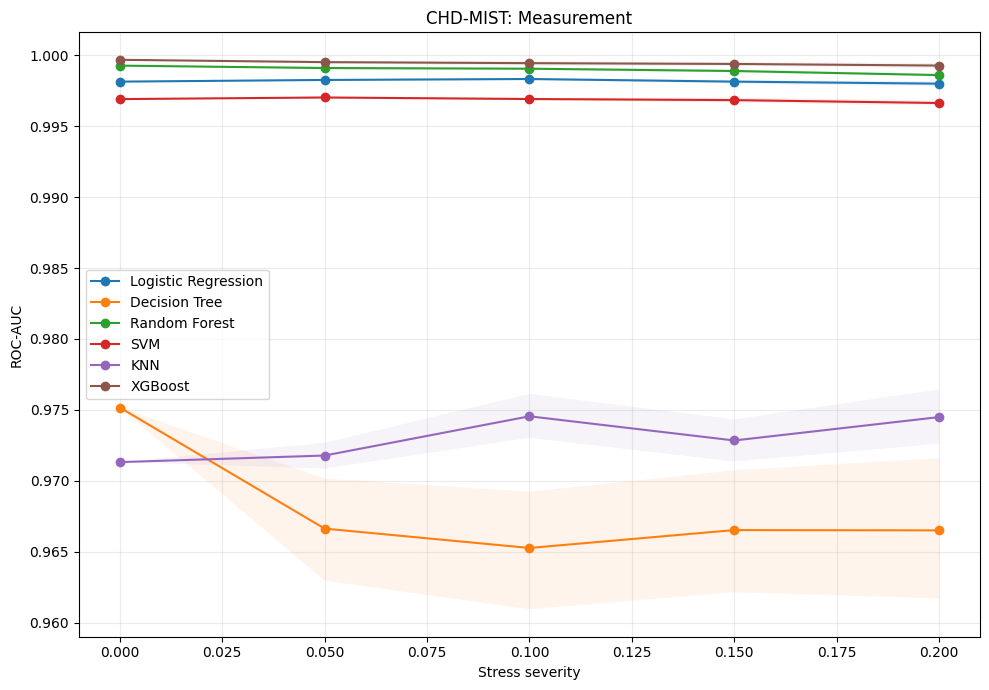

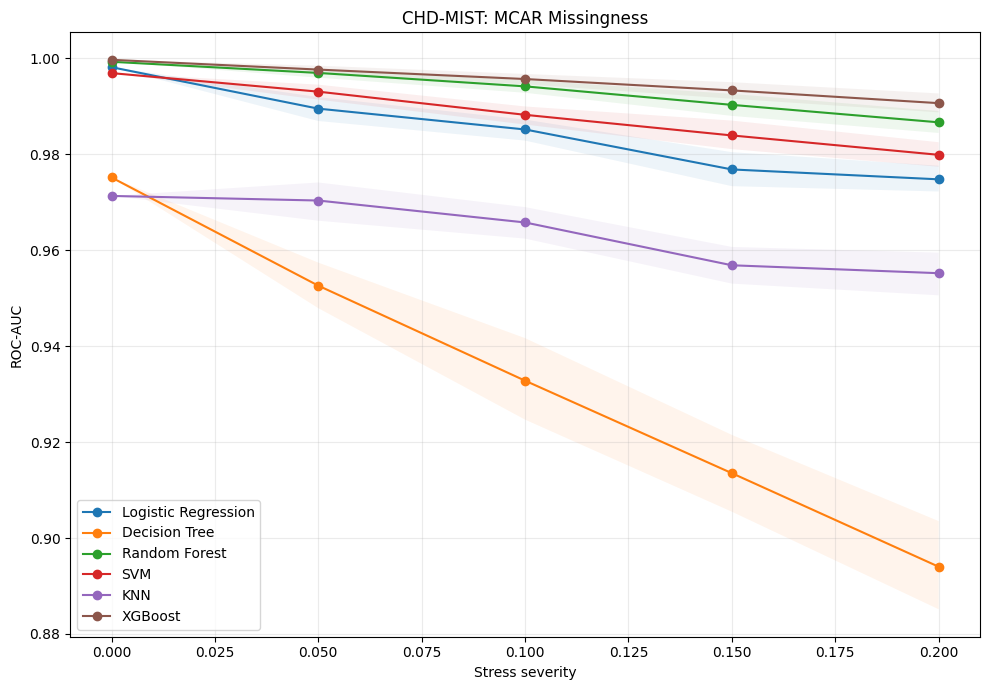

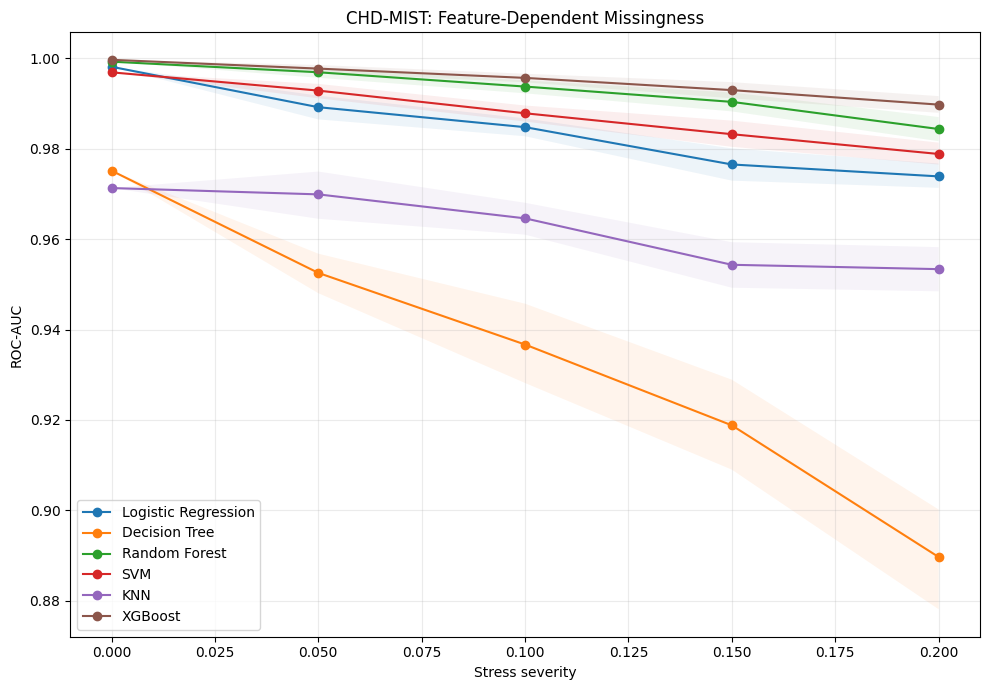

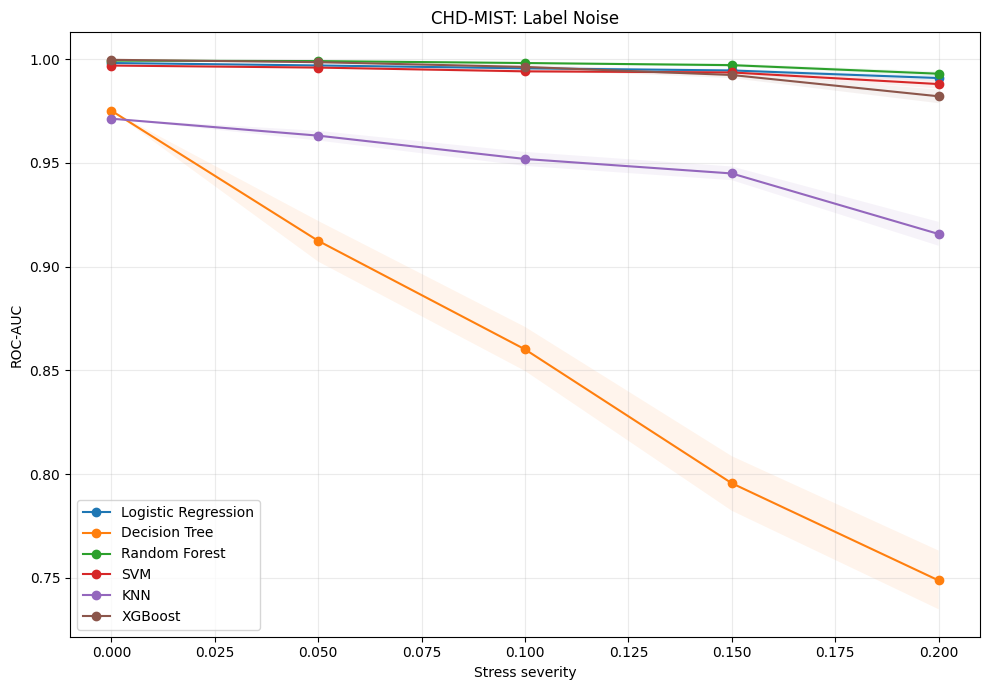

In [51]:

# Publication figure: mean AUC ± 95% CI by stress severity
for stress_type in stress_types:

    plt.figure(figsize=(10, 7))

    for model_name in models.keys():

        g = upgraded_summary[
            (upgraded_summary["Stress_Type"] == stress_type) &
            (upgraded_summary["Model"] == model_name)
        ].sort_values("Severity")

        plt.plot(
            g["Severity"],
            g["ROC_AUC_Mean"],
            marker="o",
            label=model_name
        )

        plt.fill_between(
            g["Severity"].values,
            g["ROC_AUC_CI95_Low"].values,
            g["ROC_AUC_CI95_High"].values,
            alpha=0.08
        )

    plt.xlabel("Stress severity")
    plt.ylabel("ROC-AUC")
    plt.title(f"CHD-MIST: {stress_type}")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()


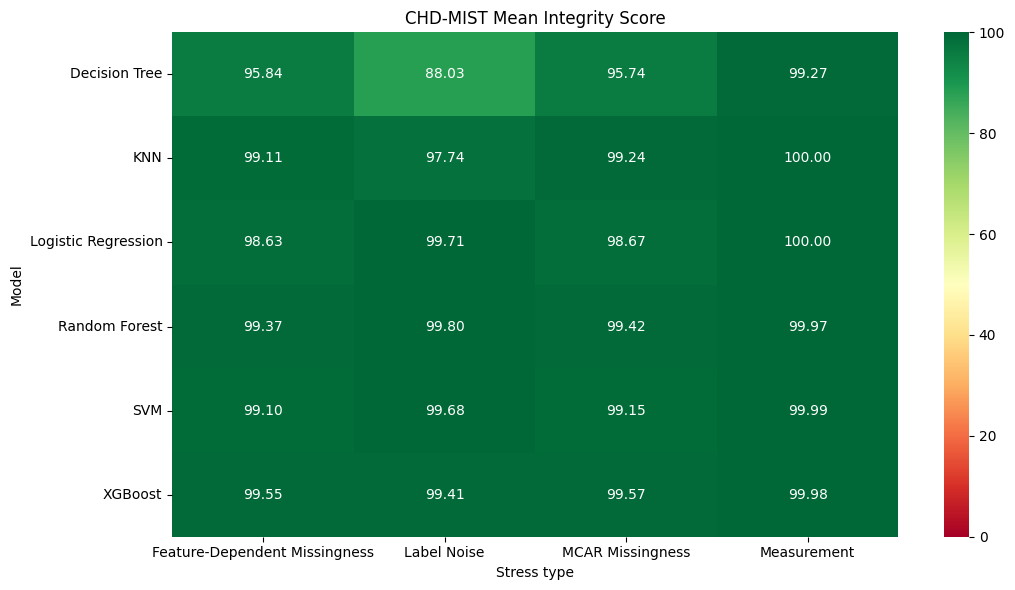

In [52]:

# Publication heatmap: mean integrity by model and stress type
heat = (
    upgraded_summary
    .groupby(["Model", "Stress_Type"])["Integrity_Score"]
    .mean()
    .unstack()
)

plt.figure(figsize=(11, 6))
sns.heatmap(
    heat,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=0,
    vmax=100
)

plt.title("CHD-MIST Mean Integrity Score")
plt.xlabel("Stress type")
plt.ylabel("Model")
plt.tight_layout()
plt.show()


In [53]:

# Export upgraded results
UPGRADED_DIR = "CHD_MIST_Upgraded_Results"
os.makedirs(UPGRADED_DIR, exist_ok=True)

upgraded_stress_results.to_csv(
    f"{UPGRADED_DIR}/upgraded_stress_results.csv",
    index=False
)

upgraded_summary.to_csv(
    f"{UPGRADED_DIR}/upgraded_stress_summary.csv",
    index=False
)

upgraded_overall.to_csv(
    f"{UPGRADED_DIR}/upgraded_integrity_scores.csv",
    index=False
)

effect_df.to_csv(
    f"{UPGRADED_DIR}/pairwise_effect_sizes.csv",
    index=False
)

baseline_df.to_csv(
    f"{UPGRADED_DIR}/baseline_results.csv",
    index=False
)

zip_path = shutil.make_archive(
    "CHD_MIST_Upgraded_Results",
    "zip",
    UPGRADED_DIR
)

print("Saved:", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("If running outside Colab, the ZIP is in the working directory.")


Saved: /content/CHD_MIST_Upgraded_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
# ============================================
# CLEAN VS STRESS RANKING CONSISTENCY ANALYSIS
# ============================================

from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

# Clean-data ranking
clean_ranking = (
    baseline_df[["Model", "ROC_AUC"]]
    .sort_values("ROC_AUC", ascending=False)
    .reset_index(drop=True)
)

clean_ranking["Clean_Rank"] = np.arange(1, len(clean_ranking) + 1)

print("CLEAN-DATA RANKING")
display(clean_ranking.round(4))

CLEAN-DATA RANKING


,Model,ROC_AUC,Clean_Rank
0,XGBoost,0.9997,1
1,Random Forest,0.9993,2
2,Logistic Regression,0.9982,3
3,SVM,0.9969,4
4,Decision Tree,0.9752,5
5,KNN,0.9713,6


In [65]:
# ============================================
# STRESS-LEVEL MODEL RANKING
# ============================================

stress_ranking = (
    upgraded_stress_results
    .groupby(["Stress_Type", "Severity", "Model"])["ROC_AUC"]
    .mean()
    .reset_index()
)

stress_ranking["Stress_Rank"] = (
    stress_ranking
    .groupby(["Stress_Type", "Severity"])["ROC_AUC"]
    .rank(
        ascending=False,
        method="min"
    )
)

print("STRESS-DATA RANKING")
display(
    stress_ranking
    .sort_values(["Stress_Type", "Severity", "Stress_Rank"])
    .round(4)
)

STRESS-DATA RANKING


,Stress_Type,Severity,Model,ROC_AUC,Stress_Rank
5,Feature-Dependent Missingness,0.0,XGBoost,0.9997,1.0
3,Feature-Dependent Missingness,0.0,Random Forest,0.9993,2.0
2,Feature-Dependent Missingness,0.0,Logistic Regression,0.9982,3.0
4,Feature-Dependent Missingness,0.0,SVM,0.9969,4.0
0,Feature-Dependent Missingness,0.0,Decision Tree,0.9752,5.0
...,...,...,...,...,...
117,Measurement,0.2,Random Forest,0.9986,2.0
116,Measurement,0.2,Logistic Regression,0.9980,3.0
118,Measurement,0.2,SVM,0.9966,4.0
115,Measurement,0.2,KNN,0.9745,5.0


In [66]:
# ============================================
# CLEAN VS STRESSED RANKING COMPARISON
# ============================================

ranking_analysis = []

for stress_type in stress_ranking["Stress_Type"].unique():

    for severity in sorted(
        stress_ranking[
            stress_ranking["Stress_Type"] == stress_type
        ]["Severity"].unique()
    ):

        stressed = stress_ranking[
            (stress_ranking["Stress_Type"] == stress_type) &
            (stress_ranking["Severity"] == severity)
        ][["Model", "Stress_Rank", "ROC_AUC"]]

        comparison = clean_ranking[
            ["Model", "Clean_Rank"]
        ].merge(
            stressed,
            on="Model"
        )

        rho, p_value = spearmanr(
            comparison["Clean_Rank"],
            comparison["Stress_Rank"]
        )

        comparison["Rank_Change"] = (
            comparison["Stress_Rank"]
            - comparison["Clean_Rank"]
        )

        comparison["Stress_Type"] = stress_type
        comparison["Severity"] = severity
        comparison["Spearman_Rho"] = rho
        comparison["Spearman_P"] = p_value

        ranking_analysis.append(comparison)

ranking_analysis_df = pd.concat(
    ranking_analysis,
    ignore_index=True
)

print("CLEAN VS STRESSED RANKING")
display(ranking_analysis_df.round(4))

CLEAN VS STRESSED RANKING


,Model,Clean_Rank,Stress_Rank,ROC_AUC,Rank_Change,Stress_Type,Severity,Spearman_Rho,Spearman_P
0,XGBoost,1,1.0,0.9997,0.0,Feature-Dependent Missingness,0.0,1.0000,0.0000
1,Random Forest,2,2.0,0.9993,0.0,Feature-Dependent Missingness,0.0,1.0000,0.0000
2,Logistic Regression,3,3.0,0.9982,0.0,Feature-Dependent Missingness,0.0,1.0000,0.0000
3,SVM,4,4.0,0.9969,0.0,Feature-Dependent Missingness,0.0,1.0000,0.0000
4,Decision Tree,5,5.0,0.9752,0.0,Feature-Dependent Missingness,0.0,1.0000,0.0000
...,...,...,...,...,...,...,...,...,...
115,Random Forest,2,2.0,0.9986,0.0,Measurement,0.2,0.9429,0.0048
116,Logistic Regression,3,3.0,0.9980,0.0,Measurement,0.2,0.9429,0.0048
117,SVM,4,4.0,0.9966,0.0,Measurement,0.2,0.9429,0.0048
118,Decision Tree,5,6.0,0.9665,1.0,Measurement,0.2,0.9429,0.0048


In [69]:
# ============================================
# FINAL ROBUSTNESS RANKING
# ============================================

final_robustness = (
    upgraded_overall[
        [
            "Model",
            "Mean_Integrity_Score",
            "Worst_Integrity_Score",
            "Integrity_CI95_Low",
            "Integrity_CI95_High"
        ]
    ]
    .sort_values(
        "Mean_Integrity_Score",
        ascending=False
    )
    .reset_index(drop=True)
)

final_robustness["Robustness_Rank"] = (
    np.arange(1, len(final_robustness) + 1)
)

print("FINAL ROBUSTNESS RANKING")
display(final_robustness.round(4))

FINAL ROBUSTNESS RANKING


,Model,Mean_Integrity_Score,Worst_Integrity_Score,Integrity_CI95_Low,Integrity_CI95_High,Robustness_Rank
0,Random Forest,99.6400,97.3092,99.5859,99.6918,1
1,XGBoost,99.6269,95.9450,99.5738,99.6765,2
2,SVM,99.4799,97.0043,99.4096,99.5488,3
3,Logistic Regression,99.2540,96.3603,99.1555,99.3505,4
4,KNN,99.0672,92.1602,98.9074,99.2251,5
5,Decision Tree,94.7189,71.1008,94.0844,95.3389,6


In [70]:
# ============================================
# CLEAN PERFORMANCE VS ROBUSTNESS
# ============================================

final_comparison = (
    clean_ranking[
        ["Model", "Clean_Rank", "ROC_AUC"]
    ]
    .merge(
        final_robustness[
            [
                "Model",
                "Robustness_Rank",
                "Mean_Integrity_Score",
                "Worst_Integrity_Score"
            ]
        ],
        on="Model"
    )
)

final_comparison["Rank_Difference"] = (
    final_comparison["Robustness_Rank"]
    - final_comparison["Clean_Rank"]
)

print("CLEAN PERFORMANCE VS ROBUSTNESS")
display(final_comparison.round(4))

CLEAN PERFORMANCE VS ROBUSTNESS


,Model,Clean_Rank,ROC_AUC,Robustness_Rank,Mean_Integrity_Score,Worst_Integrity_Score,Rank_Difference
0,XGBoost,1,0.9997,2,99.6269,95.9450,1
1,Random Forest,2,0.9993,1,99.6400,97.3092,-1
2,Logistic Regression,3,0.9982,4,99.2540,96.3603,1
3,SVM,4,0.9969,3,99.4799,97.0043,-1
4,Decision Tree,5,0.9752,6,94.7189,71.1008,1
5,KNN,6,0.9713,5,99.0672,92.1602,-1
